In [1]:
# Setup: run from the project folder, fix seeds, build the training pipeline
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import random
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from captioning.clean import load_config
from captioning.pipeline import make_dataset, load_vocab

cfg = load_config()
random.seed(cfg["seed"])
np.random.seed(cfg["seed"])
tf.random.set_seed(cfg["seed"])

vocab = load_vocab(cfg)
id_to_word = {i: w for w, i in vocab.items()}
FIG_DIR = Path("reports/figures")

train_ds = make_dataset("train", cfg)
print("Working folder:", Path.cwd())
print("Vocabulary size:", len(vocab))

Working folder: c:\Users\User\Downloads\pr7615\Image-captioning
Vocabulary size: 2533


images      (64, 224, 224, 3) <dtype: 'float32'>
caption_in  (64, 23) <dtype: 'int32'>
caption_out (64, 23) <dtype: 'int32'>
Every caption_in starts with <start>: True
Every caption_out contains <end>: True
Token IDs range from 0 to 2529 (vocabulary IDs are 0 to 2532)


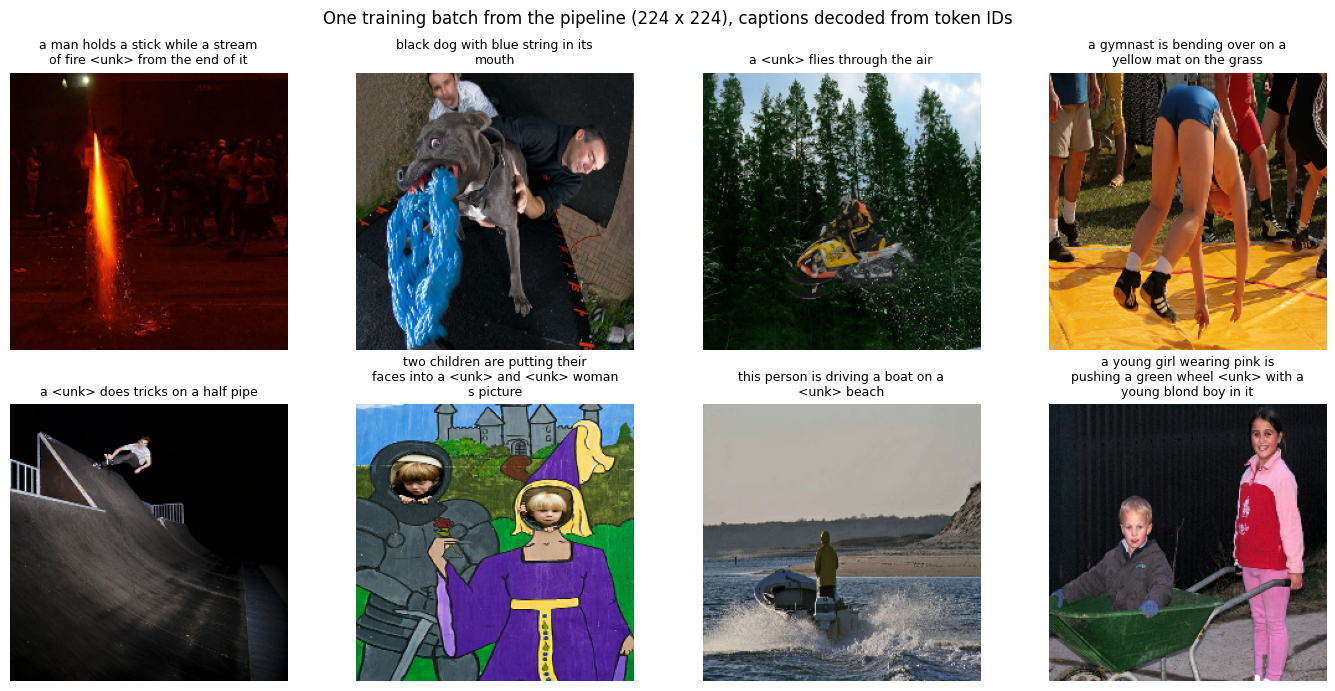

In [2]:
# One batch from the end of the pipeline, preprocessing undone, captions decoded from the batch
import textwrap

(images, caption_in), caption_out = next(iter(train_ds))
print("images     ", images.shape, images.dtype)
print("caption_in ", caption_in.shape, caption_in.dtype)
print("caption_out", caption_out.shape, caption_out.dtype)
print("Every caption_in starts with <start>:",
      bool(tf.reduce_all(caption_in[:, 0] == vocab["<start>"])))
print("Every caption_out contains <end>:",
      bool(tf.reduce_all(tf.reduce_any(caption_out == vocab["<end>"], axis=1))))
print(f"Token IDs range from {int(tf.reduce_min(caption_out))} to "
      f"{int(tf.reduce_max(caption_out))} (vocabulary IDs are 0 to {len(vocab) - 1})")

def decode(ids):
    words = []
    for i in ids.numpy():
        word = id_to_word[int(i)]
        if word == "<start>":
            continue
        if word in ("<end>", "<pad>"):
            break
        words.append(word)
    return " ".join(words)

def undo_resnet(x):
    """Reverse ResNet-50 preprocessing: add the ImageNet mean back, BGR -> RGB."""
    x = x + tf.constant([103.939, 116.779, 123.68])
    x = x[..., ::-1]
    return tf.clip_by_value(x, 0, 255).numpy().astype("uint8")

shown = undo_resnet(images[:8])
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for k, ax in enumerate(axes.flat):
    ax.imshow(shown[k])
    ax.set_title("\n".join(textwrap.wrap(decode(caption_in[k]), 35)), fontsize=9)
    ax.axis("off")
fig.suptitle("One training batch from the pipeline (224 x 224), captions decoded from token IDs",
             fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig7_pipeline_batch.png", dpi=200)
plt.show()

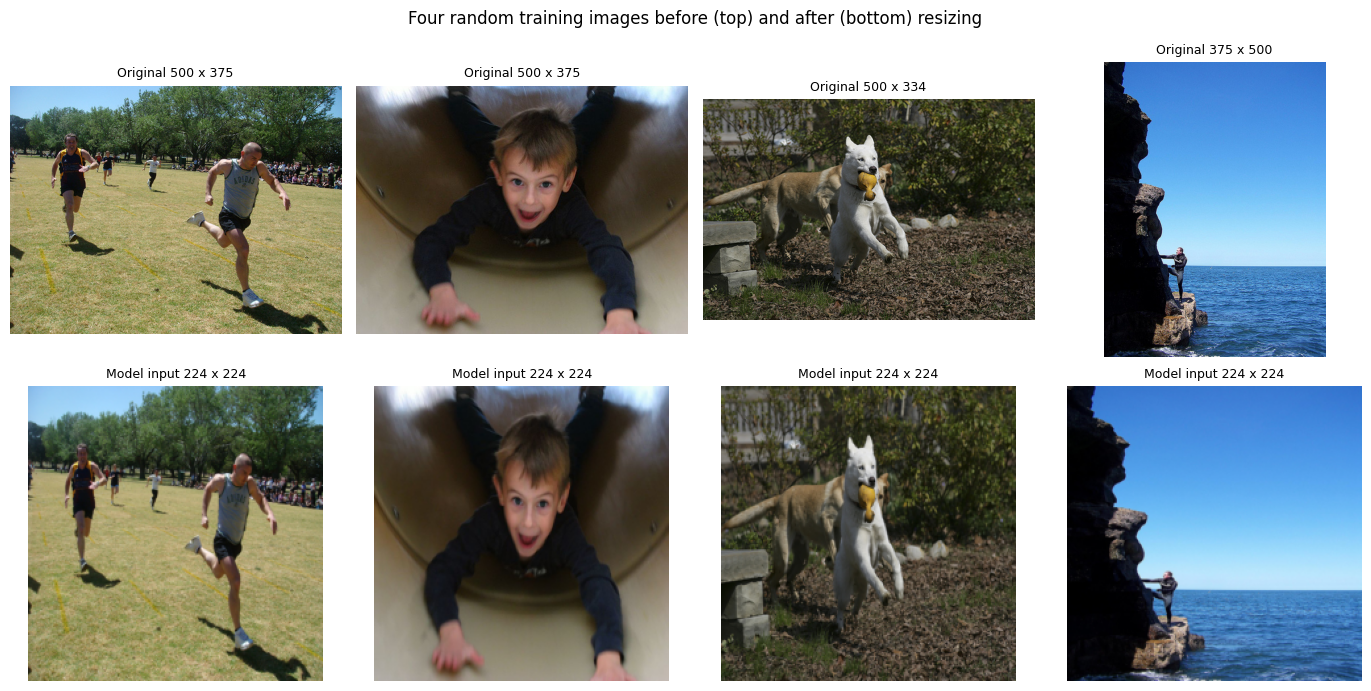

In [3]:
# Resize check: original vs 224 x 224 squashed, for 4 random training images
from PIL import Image
import pandas as pd

df = pd.read_csv(Path(cfg["paths"]["processed"]) / "captions_split.csv")
train_names = sorted(df.loc[df["split"] == "train", "image"].unique())
rng = np.random.default_rng(cfg["seed"])
picked = rng.choice(train_names, size=4, replace=False)
image_dir = Path(cfg["paths"]["raw_images"])
size = cfg["image_size"]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for col, name in enumerate(picked):
    with Image.open(image_dir / name) as img:
        original = img.copy()
    squashed = original.resize((size, size), Image.BILINEAR)
    axes[0, col].imshow(original)
    axes[0, col].set_title(f"Original {original.size[0]} x {original.size[1]}", fontsize=9)
    axes[1, col].imshow(squashed)
    axes[1, col].set_title(f"Model input {size} x {size}", fontsize=9)
    for row in (0, 1):
        axes[row, col].axis("off")

fig.suptitle("Four random training images before (top) and after (bottom) resizing", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig8_resize_check.png", dpi=200)
plt.show()

Parameters: 339,109
Random-guess loss would be ln(2533) = 7.84
Loss before training: 7.847
Epoch 1/10


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


30/30 - 5s - 162ms/step - loss: 7.7227
Epoch 2/10
30/30 - 3s - 99ms/step - loss: 7.2619
Epoch 3/10
30/30 - 3s - 102ms/step - loss: 6.5436
Epoch 4/10
30/30 - 3s - 101ms/step - loss: 6.0330
Epoch 5/10
30/30 - 3s - 98ms/step - loss: 5.5241
Epoch 6/10
30/30 - 3s - 109ms/step - loss: 5.2866
Epoch 7/10
30/30 - 3s - 99ms/step - loss: 5.1283
Epoch 8/10
30/30 - 3s - 98ms/step - loss: 4.9290
Epoch 9/10
30/30 - 3s - 97ms/step - loss: 4.8275
Epoch 10/10
30/30 - 3s - 99ms/step - loss: 4.7170


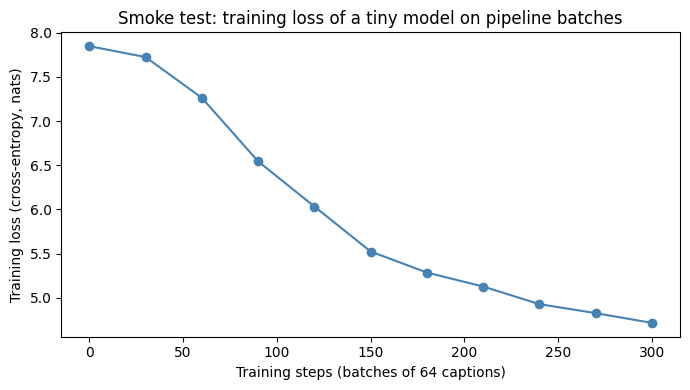

Loss went from 7.847 to 4.717


In [4]:
# Smoke test: tiny model trained for 300 steps on pipeline batches
from tensorflow import keras
from tensorflow.keras import layers

seq_len = caption_in.shape[1]
vocab_size = len(vocab)

image_input = keras.Input(shape=(224, 224, 3), name="image")
caption_input = keras.Input(shape=(seq_len,), dtype="int32", name="caption_in")
x = layers.AveragePooling2D(pool_size=28)(image_input)    # shrink to 8 x 8 x 3
x = layers.Flatten()(x)
x = layers.Rescaling(1 / 127.5)(x)
x = layers.Dense(64)(x)
x = layers.RepeatVector(seq_len)(x)                       # same image vector at every word
words = layers.Embedding(vocab_size, 64)(caption_input)
h = layers.Add()([x, words])
logits = layers.Dense(vocab_size)(h)                      # one score per vocabulary word
model = keras.Model([image_input, caption_input], logits)

model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss=keras.losses.SparseCategoricalCrossentropy(
                  from_logits=True, ignore_class=0))      # ignore <pad> positions
print(f"Parameters: {model.count_params():,}")
print(f"Random-guess loss would be ln({vocab_size}) = {np.log(vocab_size):.2f}")

start_loss = model.evaluate(train_ds.take(5), verbose=0)
print(f"Loss before training: {start_loss:.3f}")

history = model.fit(train_ds.repeat(), steps_per_epoch=30, epochs=10, verbose=2)
losses = [start_loss] + history.history["loss"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(0, 301, 30), losses, marker="o", color="steelblue")
ax.set_xlabel("Training steps (batches of 64 captions)")
ax.set_ylabel("Training loss (cross-entropy, nats)")
ax.set_title("Smoke test: training loss of a tiny model on pipeline batches")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig9_smoke_loss.png", dpi=200)
plt.show()
print(f"Loss went from {losses[0]:.3f} to {losses[-1]:.3f}")

In [5]:
# Measured cost: one full pass of the training data through the pipeline
def time_one_pass(ds):
    start = time.perf_counter()
    batches = 0
    for _ in ds:
        batches += 1
    return time.perf_counter() - start, batches

timing_ds = make_dataset("train", cfg)
first_pass, n_batches = time_one_pass(timing_ds)    # reads JPEGs from disk, fills the cache
cached_pass, _ = time_one_pass(timing_ds)           # images now come from the memory cache

print(f"Platform: {tf.config.list_physical_devices('GPU') or 'CPU only'}")
print(f"Batches per pass: {n_batches} (30,000 captions / 64)")
print(f"First pass (from disk, fills cache): {first_pass:.1f} s")
print(f"Later passes (from memory cache):    {cached_pass:.1f} s")

Platform: CPU only
Batches per pass: 469 (30,000 captions / 64)
First pass (from disk, fills cache): 46.3 s
Later passes (from memory cache):    36.8 s
